# Домашнее задание №2 по A/B-тестированию

**Выполнил:** Ожиганов В. В.  
**Группа:** М26-555

# Задача: Анализ эффективности нового алгоритма рекомендаций в условиях асимметричного и зашумленного распределения
### Контекст:
Крупная стриминговая платформа (аналог YouTube или Twitch) разработала новый алгоритм рекомендаций контента (алгоритм B), который, как ожидается, должен увеличить среднее время просмотра на пользователя по сравнению со старым алгоритмом (A).

Было проведено A/B-тестирование:

- **Группа A (Контрольная)**: 5000 пользователей, старый алгоритм.

- **Группа B (Тестовая)**: 5000 пользователей, новый алгоритм.

По итогам двухнедельного теста вы собрали данные по ключевой метрике — **«Общее время просмотра на пользователя за тест (в минутах)»**.

**Данные и их особенности:**

**Не нормальность:** Распределение метрики в обеих группах сильно отличается от нормального. Оно имеет типичный для поведенческих данных "длинный хвост":

- Большинство пользователей смотрят немного (пик в районе 0-50 минут).

- Небольшая группа "супер-зрителей" смотрит очень много (сотни и тысячи минут), формируя длинный правый хвост распределения.

**Асимметрия влияния:** Новый алгоритм B целенаправленно меняет опыт именно активных пользователей, в то время как для "пассивных" зрителей разница неочевидна. Это означает, что различие между группами может быть не сдвигом всего распределения, а изменением в правом хвосте.

**Наличие выбросов:** В данных присутствуют экстремальные выбросы (например, пользователи, которые оставляли видео фоном на всю ночь).

Вам предоставлен датасет _ab_test_results.csv_ со следующими колонками:

 - _user_id_

 - _group (A или B)_

 - _total_watch_time_min_

### Задания:


- **Проведите тест Манна-Уитни (Mann-Whitney U test)**. Сформулируйте нулевую и альтернативную гипотезы. Интерпретируйте p-value. Можно ли на его основе сделать однозначный вывод о превосходстве алгоритма B?

- Чтобы исследовать "асимметричное влияние", проведите анализ разниц не только в центре распределения, но и в хвостах. **Рассчитайте и визуализируйте разницу между группами для 75-го, 90-го и 95-го процентилей**.

- **Сформулируйте итоговый вывод:**

    - Эффективен ли новый алгоритм B?

    - На какую именно группу пользователей он оказывает наибольшее влияние?

    - Какой метод анализа оказался наиболее информативным в данном случае и почему?

    - Дайте рекомендацию о возможности запуска алгоритма на всю аудиторию.



## 1. Загрузка и описание данных
Откройте папку ab_course в VS Code. Файл ab_test_results.csv должен лежать рядом с ноутбуком.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('ab_test_results.csv')
metric = 'total_watch_time_min'
assert df[['user_id', 'group', metric]].notna().all().all()
assert df.user_id.is_unique and set(df.group) == {'A', 'B'}
assert np.isfinite(df[metric]).all() and df[metric].ge(0).all()

a = df.loc[df.group == 'A', metric].to_numpy()
b = df.loc[df.group == 'B', metric].to_numpy()
print(f'Уникальных пользователей: {len(df)}, группа A: {len(a)}, группа B: {len(b)}')
print(df.groupby('group')[metric].describe().round(2).to_string())

Уникальных пользователей: 10000, группа A: 5000, группа B: 5000
        count   mean     std  min    25%    50%    75%       max
group                                                           
A      5000.0  56.35  262.31  0.0  14.73  26.83  44.95   8130.55
B      5000.0  71.48  408.52  0.0  15.38  27.35  46.35  11670.62


В каждой группе по 5000 пользователей. Средние заметно выше медиан: большие значения справа тянут среднее вверх. Длинные просмотры сохраняем: по общей длительности нельзя отличить фоновый просмотр от реального.

## 2. Тест Манна–Уитни
H₀: распределения времени просмотра в A и B одинаковы. H₁: распределения различаются. Используем двусторонний тест для независимых групп при α = 0,05, как в шаблоне. Тест сравнивает ранги и не проверяет гипотезу о равенстве средних.

In [2]:
u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
print(f'U для группы A: {u:.0f}; p-value: {p:.6f}')
print(f'Доля пар, в которых B выше A (равенство дает полбалла): {1 - u / (len(a)*len(b)):.2%}')

U для группы A: 12211099; p-value: 0.045342
Доля пар, в которых B выше A (равенство дает полбалла): 51.16%


При верной H₀ вероятность получить не менее экстремальную U-статистику составляет около 4,53%. На уровне 5% отвергаем H₀, но преимущество по рангам невелико: случайный пользователь B опережает случайного пользователя A примерно в 51,2% сравнений с учетом равенств.

## 3. Сравнение центра и правого хвоста
Сравним медиану и четыре верхних процентиля. Положительная разница означает, что в группе B порог времени просмотра выше.

In [3]:
levels = [50, 75, 90, 95, 99]
table = pd.DataFrame({'A': np.percentile(a, levels), 'B': np.percentile(b, levels)},
                     index=levels)
table.index.name = 'Процентиль'
table['B − A'] = table.B - table.A
print(table.round(2).to_string())

                 A       B   B − A
Процентиль                        
50           26.83   27.35    0.52
75           44.95   46.35    1.41
90           71.52   76.24    4.72
95          119.34  153.62   34.28
99          435.58  585.91  150.33


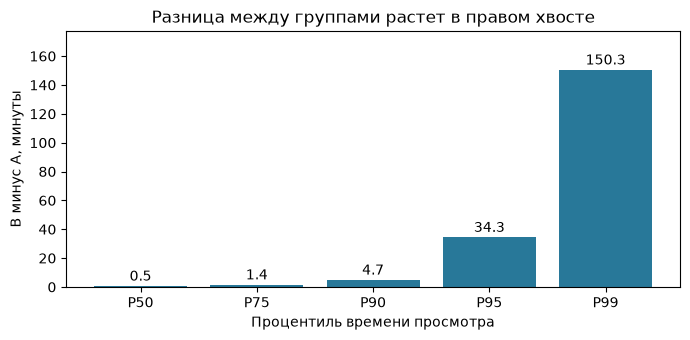

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar([f'P{x}' for x in levels], table['B − A'], color='#287899')
for bar, delta in zip(bars, table['B − A']):
    ax.annotate(f'{delta:.1f}', (bar.get_x() + bar.get_width()/2, delta),
                xytext=(0, 4), textcoords='offset points', ha='center')
ax.set(title='Разница между группами растет в правом хвосте',
       ylabel='B минус A, минуты', xlabel='Процентиль времени просмотра')
ax.margins(y=0.18)
plt.tight_layout()
plt.show()

Медианы различаются всего на 0,52 минуты. На P95 разница достигает 34,28 минуты, на P99 уже 150,33 минуты. Это разница между порогами двух распределений, а не индивидуальная прибавка для каждого активного зрителя.

## 4. Эффект на среднее и рекомендация
Среднее время просмотра было целью эксперимента. Оценим разницу B − A и приближенный 95%-й доверительный интервал Уэлча для независимых групп с разными дисперсиями.

In [5]:
diff = b.mean() - a.mean()
va, vb = a.var(ddof=1)/len(a), b.var(ddof=1)/len(b)
df_welch = (va + vb)**2 / (va**2/(len(a)-1) + vb**2/(len(b)-1))
margin = stats.t.ppf(0.975, df_welch) * np.sqrt(va + vb)
print(f'Разница средних: {diff:+.2f} мин. ({diff/a.mean():+.1%})')
print(f'95%-й ДИ: от {diff-margin:.2f} до {diff+margin:.2f} мин.')

Разница средних: +15.13 мин. (+26.9%)
95%-й ДИ: от 1.67 до 28.59 мин.


**Вывод.** За две недели среднее время просмотра в B выше на 15,13 минуты на пользователя (+26,9%); приближенный 95%-й интервал разницы составляет от +1,67 до +28,59 минуты. Для понимания результата полезнее всего сравнение процентилей: преимущество сосредоточено в верхнем хвосте, тогда как в центре группы почти не различаются. Чтобы проверить эффект именно у ранее активных зрителей, нужно выделить их по истории до эксперимента.

**Рекомендация:** расширять запуск поэтапно.  Перед переходом на всю аудиторию проверить по логам, сколько дополнительного времени приходится на фоновые сессии, и повторить оценку среднего на более длительном периоде. Если прирост сохраняется для осмысленных просмотров, расширить запуск.